# 08 - Sepsis care-bundle scorecard

How many patients receive the key early sepsis care steps on time, and is that changing over time?

The scorecard is **adapted** from the Surviving Sepsis Campaign hour-1 bundle, using only what the event log records:

| Element | Who it applies to |
|---|---|
| Lactate measured within 1 hour | all patients |
| Antibiotics within 1 hour (and 3 hours as a looser reference) | all patients |
| IV fluid within 3 hours | patients with hypotension |
| Lactate measured again | patients whose first lactate is above 2 |
| **All applicable elements met** | every patient |

> **Limits:** this is not an official quality measure. The clock starts at ER registration because the log has no time of sepsis recognition, and blood cultures and vasopressors are not recorded. Definitions should be confirmed with the mentor.

The monthly trend is a **control chart** (p-chart): a month is flagged only when it differs by more than chance would explain.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent
sys.path.append(str(ROOT / 'src'))

from bundle import ELEMENTS, bundle_table, control_chart, scorecard
from conformance import load_log
from plot_style import apply_style, save_fig, BLUE, INK, INK_SECONDARY
from prepare_log import load_cases

apply_style()
ORANGE = '#eb6834'  # used only to mark control-chart signals
table = bundle_table(load_log())
card = scorecard(table)
n = len(table)
print(f'{n} patients')

995 patients


## 1. The scorecard

In [2]:
card.assign(met_pct=card['met_pct'].round(1))[['label', 'applicable', 'met', 'met_pct']]

,label,applicable,met,met_pct
0,Lactate measured within 1 hour,995,758,76.2
1,Antibiotics within 1 hour,995,259,26.0
2,Antibiotics within 3 hours,995,558,56.1
3,IV fluid within 3 hours (patients with hypoten...,49,37,75.5
4,Lactate measured again (first lactate above 2),285,102,35.8
5,All applicable elements met,995,183,18.4


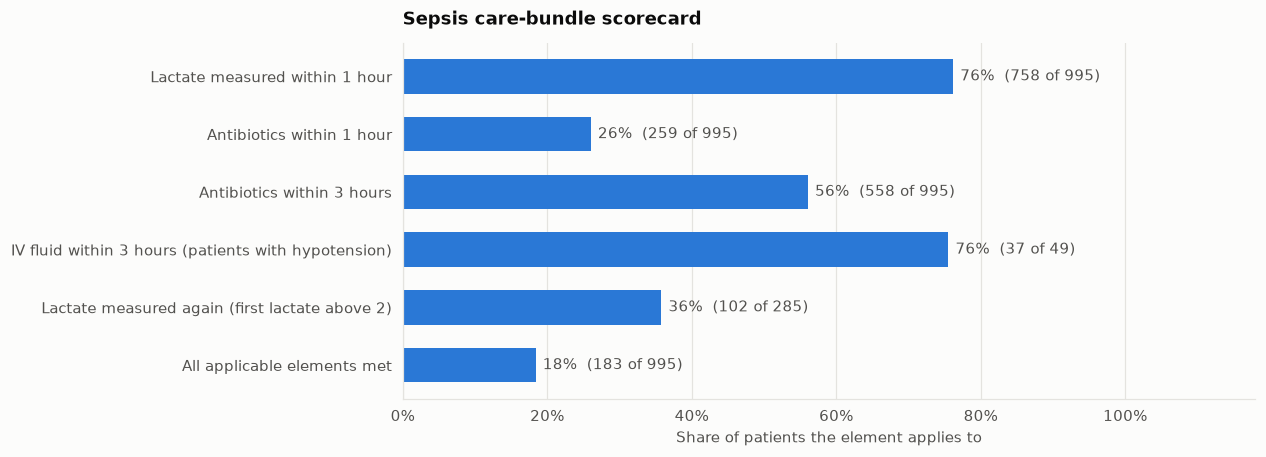

In [3]:
plot = card.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(plot['label'], plot['met_pct'], color=BLUE, height=0.6)
ax.grid(axis='y', visible=False)
for i, (m, a, p) in enumerate(zip(plot['met'], plot['applicable'], plot['met_pct'])):
    ax.text(p + 1, i, f'{p:.0f}%  ({m} of {a})', va='center', color=INK_SECONDARY, fontsize=10)
ax.set_xlim(0, 118)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%' if v <= 100 else '')
ax.set_title('Sepsis care-bundle scorecard')
ax.set_xlabel('Share of patients the element applies to')
save_fig(fig, 'bundle_scorecard')
plt.show()

## 2. Is care improving? Control charts by month
Points are monthly rates. The dashed line is the overall average; the grey lines are the control limits (3 standard errors). Orange points are signals.

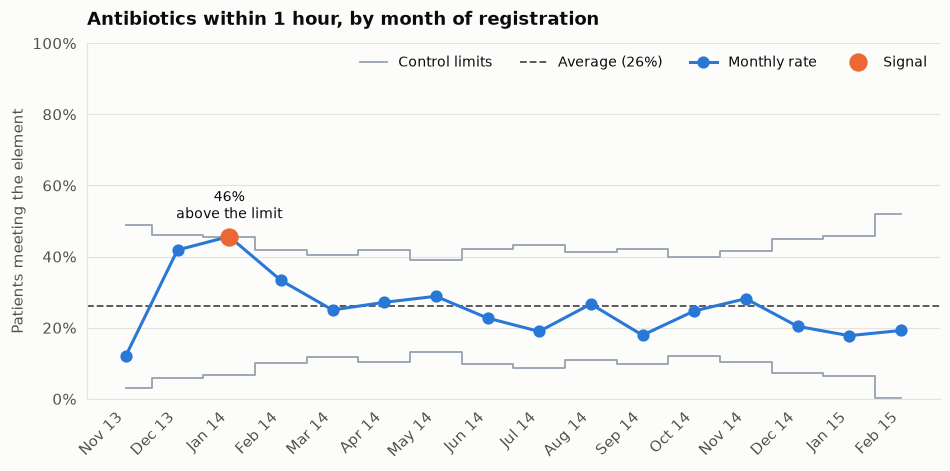

,month,n,met,pct,center,ucl,lcl,signal
0,2013-11,33,4,12.1,26.0,48.9,3.1,
1,2013-12,43,18,41.9,26.0,46.1,6.0,
2,2014-01,46,21,45.7,26.0,45.4,6.6,above the limit
3,2014-02,69,23,33.3,26.0,41.9,10.2,
4,2014-03,84,21,25.0,26.0,40.4,11.7,
5,2014-04,70,19,27.1,26.0,41.8,10.3,
6,2014-05,104,30,28.8,26.0,38.9,13.1,
7,2014-06,66,15,22.7,26.0,42.2,9.8,
8,2014-07,58,11,19.0,26.0,43.3,8.7,
9,2014-08,75,20,26.7,26.0,41.2,10.8,


In [4]:
def plot_chart(element, title, name):
    chart = control_chart(table, element)
    labels = pd.to_datetime(chart['month'] + '-01').dt.strftime('%b %y').tolist()
    x = np.arange(len(chart))
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.step(x, chart['ucl'], where='mid', color='#98a2b3', linewidth=1.2, label='Control limits')
    ax.step(x, chart['lcl'], where='mid', color='#98a2b3', linewidth=1.2)
    ax.axhline(chart['center'].iloc[0], color=INK_SECONDARY, linestyle='--', linewidth=1.2, label=f"Average ({chart['center'].iloc[0]:.0f}%)")
    ax.plot(x, chart['pct'], color=BLUE, linewidth=2, marker='o', markersize=7, label='Monthly rate')
    flagged = (chart['signal'] != '').to_numpy()
    ax.plot(x[flagged], chart.loc[flagged, 'pct'], 'o', color=ORANGE, markersize=11, label='Signal')
    for xi, (p, s) in zip(x[flagged], chart.loc[flagged, ['pct', 'signal']].itertuples(index=False)):
        ax.annotate(f'{p:.0f}%\n{s}', (xi, p), xytext=(0, 12), textcoords='offset points', ha='center', fontsize=9, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
    ax.grid(axis='x', visible=False)
    ax.set_title(title)
    ax.set_ylabel('Patients meeting the element')
    ax.legend(loc='upper right', ncol=4, frameon=False, fontsize=9)
    save_fig(fig, name)
    plt.show()
    return chart

antibiotics = plot_chart('antibiotics_1h', 'Antibiotics within 1 hour, by month of registration', 'bundle_trend_antibiotics')
antibiotics[['month', 'n', 'met', 'pct', 'center', 'ucl', 'lcl', 'signal']].round(1)

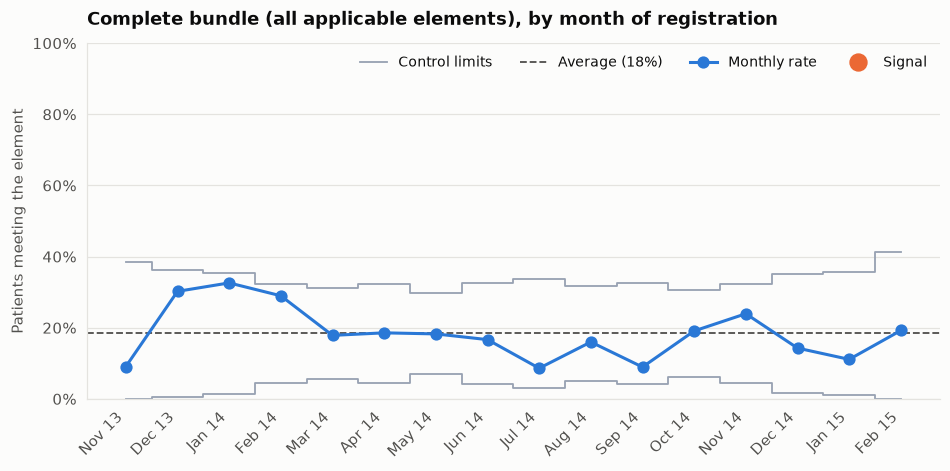

Lactate within 1 hour: monthly range 68% to 91%, average 76%, signals: 0


In [5]:
complete = plot_chart('complete_bundle', 'Complete bundle (all applicable elements), by month of registration', 'bundle_trend_complete')
lactate = control_chart(table, 'lactate_1h')
print('Lactate within 1 hour: monthly range', f"{lactate['pct'].min():.0f}% to {lactate['pct'].max():.0f}%, average {lactate['center'].iloc[0]:.0f}%, signals:", int((lactate['signal'] != '').sum()))

## 3. Who gets the complete bundle?

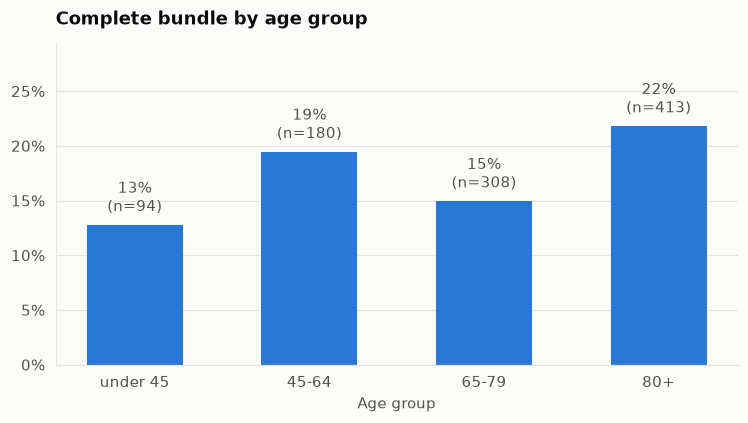

,% complete,patients
age_group,,
under 45,12.8,94
45-64,19.4,180
65-79,14.9,308
80+,21.8,413


In [6]:
merged = table.merge(load_cases()[['case:concept:name', 'age_group']], on='case:concept:name')
order = ['under 45', '45-64', '65-79', '80+']
by_age = merged.groupby('age_group')['complete_bundle'].agg(['mean', 'size']).reindex(order)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(by_age.index, by_age['mean'] * 100, color=BLUE, width=0.55)
ax.grid(axis='x', visible=False)
for i, (m, s) in enumerate(zip(by_age['mean'], by_age['size'])):
    ax.text(i, m * 100 + 0.8, f'{m * 100:.0f}%\n(n={s})', ha='center', va='bottom', color=INK_SECONDARY, fontsize=10)
ax.set_ylim(0, by_age['mean'].max() * 100 * 1.35)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.set_title('Complete bundle by age group')
ax.set_xlabel('Age group')
save_fig(fig, 'bundle_by_age')
plt.show()
by_age.assign(mean=(by_age['mean'] * 100).round(1)).rename(columns={'mean': '% complete', 'size': 'patients'})

## Findings
- **Only 18% of patients (183 of 995) receive every applicable bundle element on time.**
- **Lactate is the strongest element:** 76% have it measured within an hour of registration. Over the months the rate stays between 68% and 91%, with no signal on the control chart.
- **Antibiotics are the weakest:** 26% of all patients (33% of those who received them) get them within 1 hour, and 56% within 3 hours.
- **Fluid for hypotension:** 37 of the 49 patients with hypotension (76%) received IV fluid within 3 hours. The group is small, so this number can move a lot.
- **Repeat lactate is often missed:** of the 285 patients whose first lactate is above 2, only 102 (36%) had it measured again.
- **Care is stable but low, not improving.** The monthly rate of antibiotics within 1 hour ranges from 12% to 46%. January 2014 (46%) is the only month outside the control limits. The first months were somewhat higher (33% to 46% from December to February) and the rate then settled at 18% to 29%. Apart from January 2014, the month-to-month changes are what chance alone would produce, so there is no evidence that care got better or worse.
- **Who gets the complete bundle:** 13% of patients under 45, 19% of those aged 45 to 64, 15% of those aged 65 to 79, and 22% of those aged 80 and over. This describes the data and does not explain it.
- **Limits.** This is an adapted scorecard, not an official quality measure. The clock starts at ER registration (the log has no time of recognition), and blood cultures and vasopressors are not recorded, so the real share meeting the targets may be higher. The element definitions should be confirmed with the mentor.
